{
 "raw_shape": [
  10000,
  23
 ],
 "missing": {
  "isbn": 700,
  "isbn13": 585,
  "original_publication_year": 21,
  "original_title": 585,
  "language_code": 1084
 },
 "n_old": 379,
 "threshold": 50089.60000000002,
 "class_counts": {
  "0": 8000,
  "1": 2000
 },
 "clean_shape": [
  10000,
  26
 ],
 "desc": {
  "average_rating": {
   "count": 10000.0,
   "mean": 4.0,
   "std": 0.25,
   "min": 2.47,
   "25%": 3.85,
   "50%": 4.02,
   "75%": 4.18,
   "max": 4.82
  },
  "ratings_count": {
   "count": 10000.0,
   "mean": 54001.24,
   "std": 157369.96,
   "min": 2716.0,
   "25%": 13568.75,
   "50%": 21155.5,
   "75%": 41053.5,
   "max": 4780653.0
  },
  "books_count": {
   "count": 10000.0,
   "mean": 75.71,
   "std": 170.47,
   "min": 1.0,
   "25%": 23.0,
   "50%": 40.0,
   "75%": 67.0,
   "max": 3455.0
  },
  "original_publication_year": {
   "count": 10000.0,
   "mean": 1993.81,
   "std": 27.51,
   "min": 1900.0,
   "25%": 1990.0,
   "50%": 2004.0,
   "75%": 2011.0,
   "max": 2017.0
  

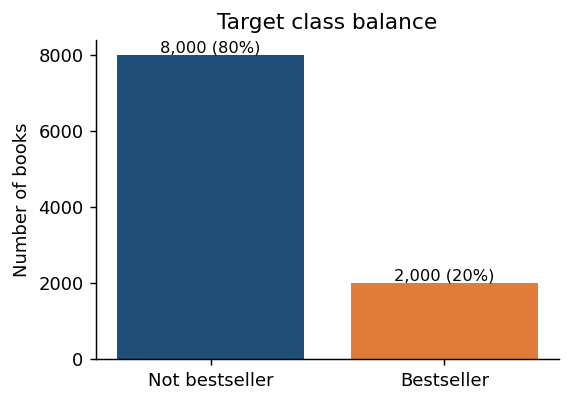

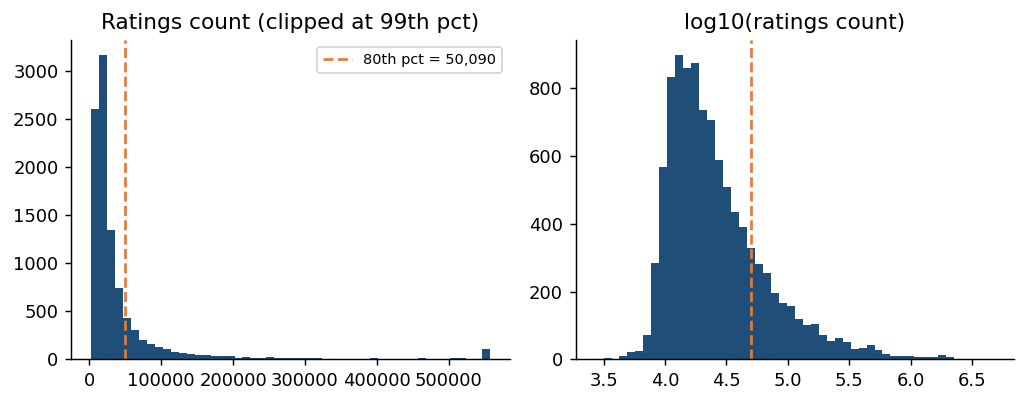

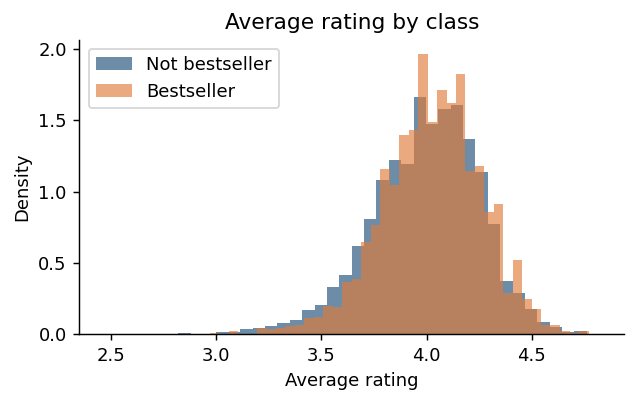

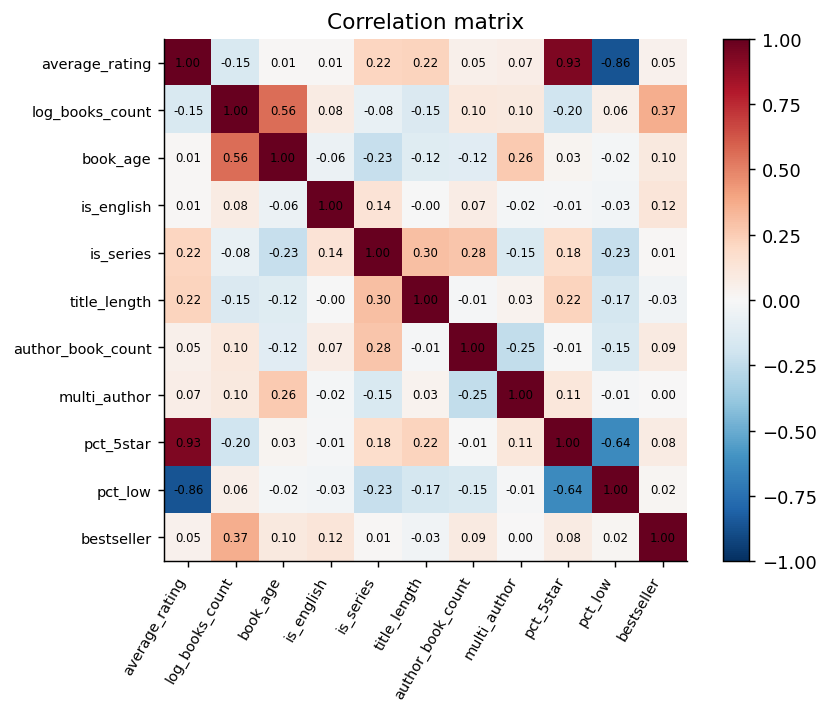

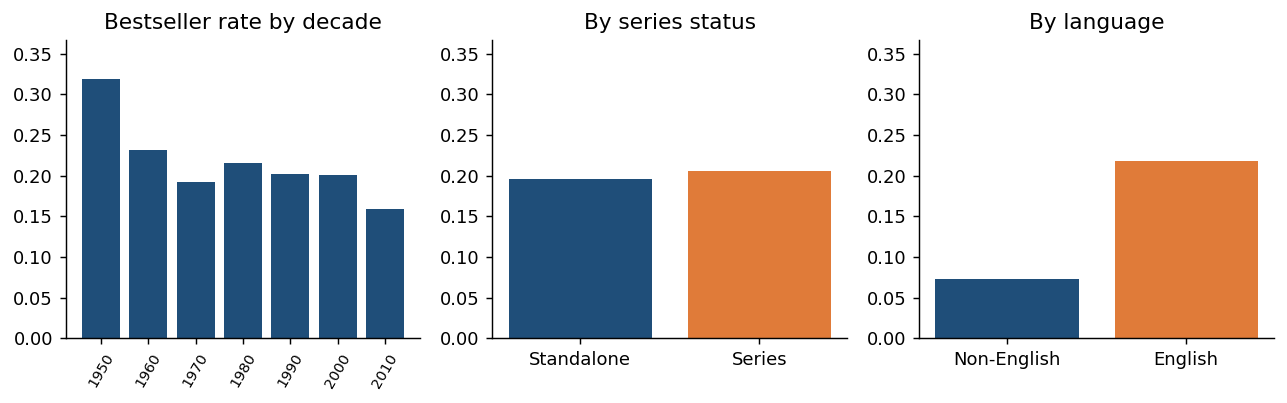

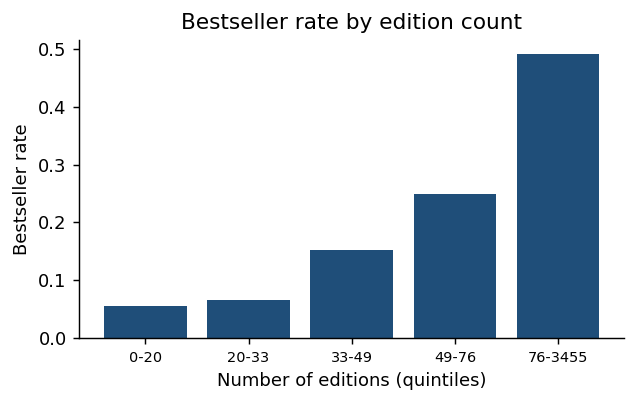

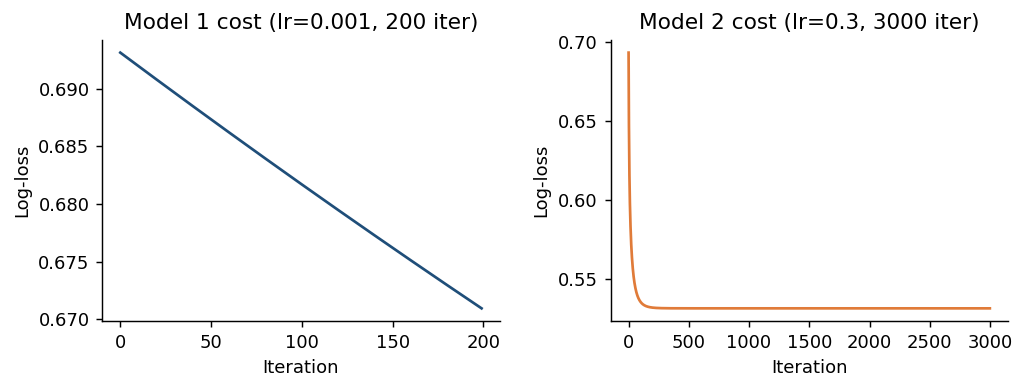

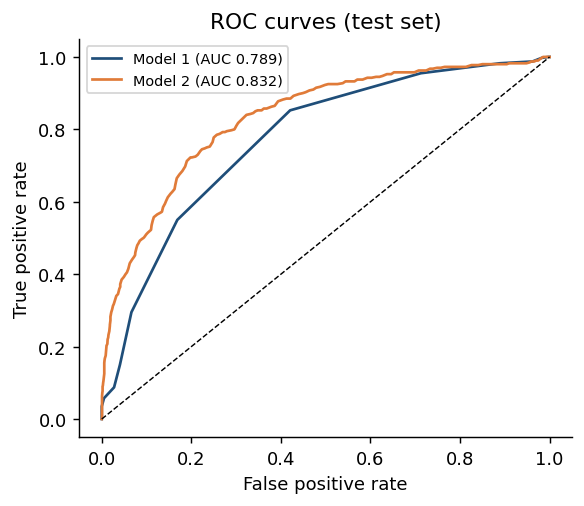

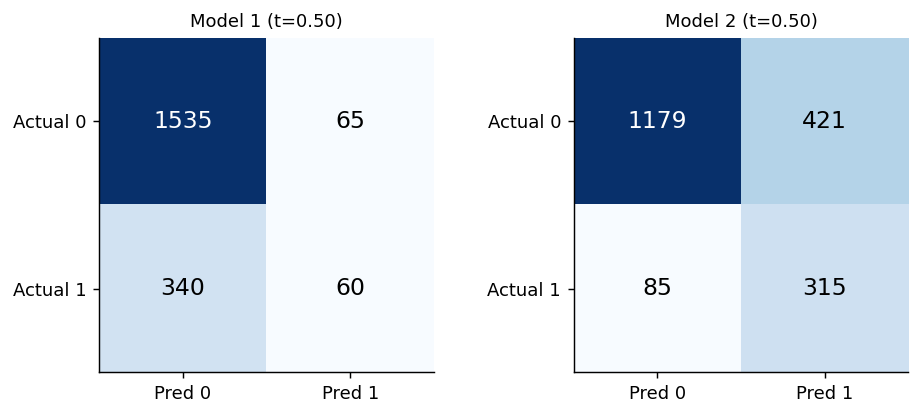

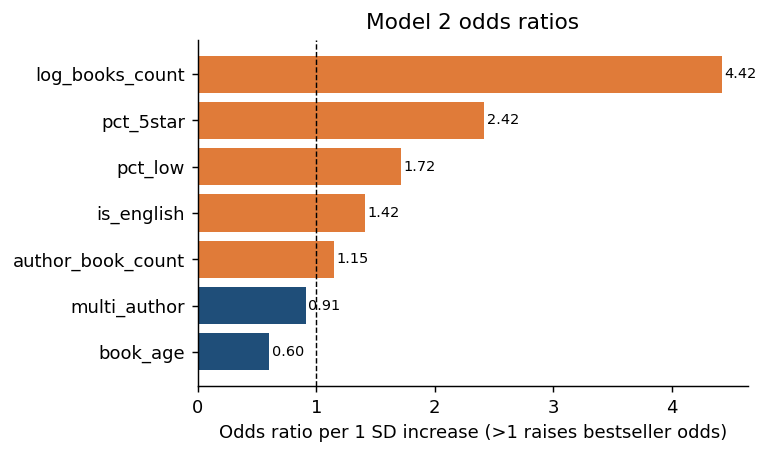

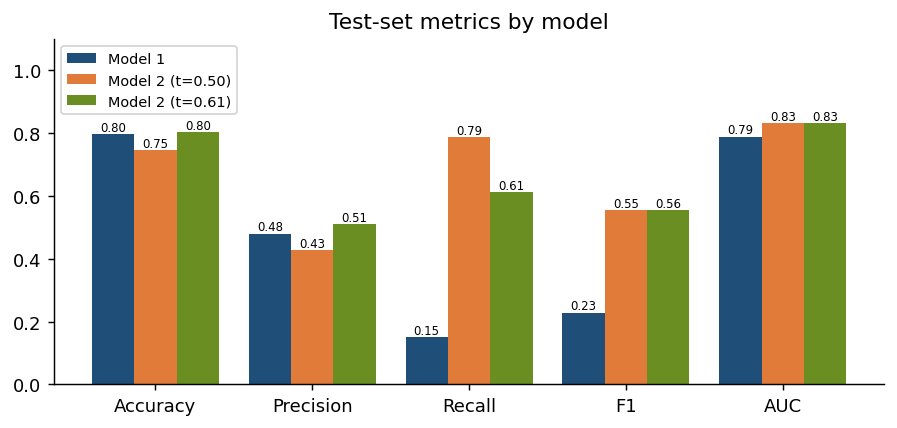

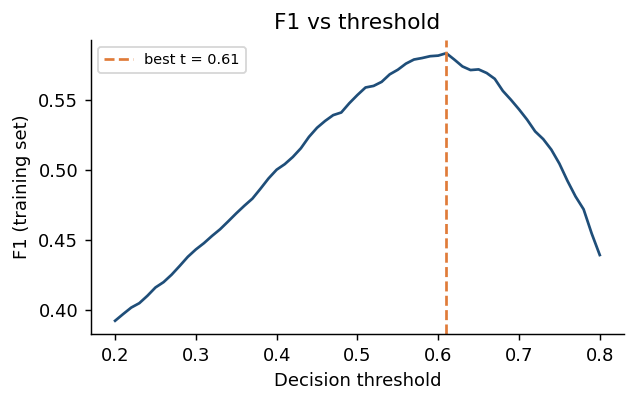

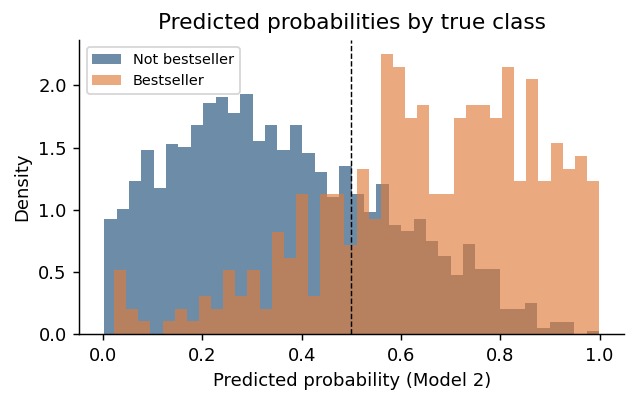

In [1]:
"""
Bestseller prediction: logistic regression from scratch (NumPy only)
====================================================================
Dataset : Goodreads "10k books" (books.csv)
Target  : bestseller = 1 if ratings_count is in the top 20% of books

Usage
-----
    python bestseller_logistic_regression.py                 # books.csv next to the script
    python bestseller_logistic_regression.py path/to/books.csv

Outputs
-------
    All figures are displayed when the code runs (nothing is saved as an image).
    stats.json (next to the script) holds every number quoted in the report.
"""
import json
import sys
from math import erf, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# Configuration
# ============================================================
SEED = 42
TOP_QUANTILE = 0.80          # bestseller = ratings_count at or above this quantile
SNAPSHOT_YEAR = 2017         # year the Goodreads snapshot ends (used for book_age)
MIN_YEAR = 1900              # earlier publication years are clipped to this
VIF_LIMIT = 5.0              # drop features whose VIF exceeds this
P_LIMIT = 0.05               # backward elimination significance level
BLUE, ORANGE, GREEN = "#1F4E79", "#E07B39", "#6B8E23"

FALLBACK_CSV = Path("C:/Users/RanwedMU/Downloads/books.csv")

DROP_COLS = ["isbn", "isbn13", "image_url", "small_image_url",
             "goodreads_book_id", "best_book_id", "work_id", "original_title"]
STAR_COLS = ["ratings_1", "ratings_2", "ratings_3", "ratings_4", "ratings_5"]
FEATURES_ALL = ["average_rating", "log_books_count", "book_age", "is_english",
                "is_series", "title_length", "author_book_count", "multi_author",
                "pct_5star", "pct_low"]

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})


# ============================================================
# Paths and small helpers
# ============================================================
def get_paths():
    """Return (base_dir, csv_path). Works as a script and as an IDE cell."""
    try:
        base = Path(__file__).resolve().parent
    except NameError:                       # Spyder / Jupyter cell: no __file__
        base = Path.cwd()

    csv_args = [a for a in sys.argv[1:] if a.lower().endswith(".csv")]
    if csv_args:
        csv_path = Path(csv_args[0])
    else:
        csv_path = base / "books.csv"
        if not csv_path.exists():
            csv_path = FALLBACK_CSV
    if not csv_path.exists():
        sys.exit(f"Could not find books.csv. Pass the path as an argument.\nLooked at: {csv_path}")
    return base, csv_path


def finish(fig):
    """Tidy the layout; the figure is displayed by plt.show() at the end of main()."""
    fig.tight_layout()


def jsonable(obj):
    """Recursively convert numpy/pandas types (including dict keys) so json.dump never fails."""
    if isinstance(obj, dict):
        out = {}
        for k, v in obj.items():
            if isinstance(k, np.generic):
                k = k.item()
            elif not (k is None or isinstance(k, (str, int, float, bool))):
                k = str(k)
            out[k] = jsonable(v)
        return out
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj


# ============================================================
# 1-4. Load, clean, target, features
# ============================================================
def load_and_clean(csv_path, stats):
    df = pd.read_csv(csv_path)
    stats["raw_shape"] = list(df.shape)
    missing = df.isna().sum()
    stats["missing"] = {k: int(v) for k, v in missing[missing > 0].items()}

    df = df.drop_duplicates(subset="book_id").copy()
    year = "original_publication_year"
    df[year] = df[year].fillna(df[year].median())
    df["language_code"] = df["language_code"].fillna("unknown")
    df = df.drop(columns=DROP_COLS, errors="ignore")

    stats["n_old"] = int((df[year] < MIN_YEAR).sum())
    df[year] = df[year].clip(lower=MIN_YEAR)
    return df


def add_target(df, stats):
    thr = df["ratings_count"].quantile(TOP_QUANTILE)
    df["bestseller"] = (df["ratings_count"] >= thr).astype(int)
    stats["threshold"] = float(thr)
    stats["class_counts"] = df["bestseller"].value_counts().to_dict()
    return thr


def engineer_features(df):
    df["is_series"] = df["title"].str.contains(r"\(.*#\d", regex=True).astype(int)
    df["title_length"] = df["title"].str.len()
    df["is_english"] = df["language_code"].str.startswith("en").astype(int)
    df["author_book_count"] = df.groupby("authors")["book_id"].transform("count")
    df["multi_author"] = df["authors"].str.contains(",").astype(int)
    df["book_age"] = SNAPSHOT_YEAR - df["original_publication_year"]
    total = df[STAR_COLS].sum(axis=1).replace(0, np.nan)      # avoid divide-by-zero
    df["pct_5star"] = (df["ratings_5"] / total).fillna(0)
    df["pct_low"] = ((df["ratings_1"] + df["ratings_2"]) / total).fillna(0)
    df["log_books_count"] = np.log1p(df["books_count"])
    df["decade"] = (df["original_publication_year"] // 10 * 10).astype(int)


# ============================================================
# 5. EDA figures
# ============================================================
def eda_figures(df, thr, stats):
    stats["clean_shape"] = list(df.shape)
    stats["desc"] = df[["average_rating", "ratings_count", "books_count",
                        "original_publication_year"]].describe().round(2).to_dict()

    # Fig 1: class balance
    fig, ax = plt.subplots(figsize=(4.5, 3.2))
    vc = df["bestseller"].value_counts().sort_index()
    ax.bar(["Not bestseller", "Bestseller"], vc.values, color=[BLUE, ORANGE])
    for i, v in enumerate(vc.values):
        ax.text(i, v + 80, f"{v:,} ({v / len(df):.0%})", ha="center", fontsize=9)
    ax.set_ylabel("Number of books"); ax.set_title("Target class balance")
    finish(fig)

    # Fig 2: ratings_count skew (justifies the top-20% cut-off)
    fig, axs = plt.subplots(1, 2, figsize=(8, 3.2))
    axs[0].hist(df["ratings_count"].clip(upper=df["ratings_count"].quantile(0.99)), bins=50, color=BLUE)
    axs[0].axvline(thr, color=ORANGE, ls="--", label=f"80th pct = {thr:,.0f}")
    axs[0].set_title("Ratings count (clipped at 99th pct)"); axs[0].legend(fontsize=8)
    axs[1].hist(np.log10(df["ratings_count"].clip(lower=1)), bins=50, color=BLUE)
    axs[1].axvline(np.log10(max(thr, 1)), color=ORANGE, ls="--")
    axs[1].set_title("log10(ratings count)")
    finish(fig)

    # Fig 3: average rating by class
    fig, ax = plt.subplots(figsize=(5, 3.2))
    for c, col, lab in [(0, BLUE, "Not bestseller"), (1, ORANGE, "Bestseller")]:
        ax.hist(df.loc[df.bestseller == c, "average_rating"], bins=40, alpha=.65,
                color=col, label=lab, density=True)
    ax.set_xlabel("Average rating"); ax.set_ylabel("Density")
    ax.legend(); ax.set_title("Average rating by class")
    finish(fig)

    # Fig 4: correlation heatmap
    corr = df[FEATURES_ALL + ["bestseller"]].corr()
    fig, ax = plt.subplots(figsize=(7, 5.6))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticklabels(corr.columns, fontsize=8)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
    fig.colorbar(im, ax=ax, fraction=.04); ax.set_title("Correlation matrix")
    finish(fig)
    stats["corr_target"] = corr["bestseller"].drop("bestseller").round(3).to_dict()
    stats["corr_rating_pct5"] = float(corr.loc["average_rating", "pct_5star"])
    stats["corr_rating_pctlow"] = float(corr.loc["average_rating", "pct_low"])

    # Fig 5: bestseller rate by decade / series / language
    dec = df[df.decade >= 1950].groupby("decade")["bestseller"].mean()
    ser = df.groupby("is_series")["bestseller"].mean()
    eng = df.groupby("is_english")["bestseller"].mean()
    fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
    axs[0].bar(dec.index.astype(str), dec.values, color=BLUE); axs[0].set_title("Bestseller rate by decade")
    axs[0].tick_params(axis="x", rotation=60, labelsize=8)
    axs[1].bar(["Standalone", "Series"], ser.values, color=[BLUE, ORANGE]); axs[1].set_title("By series status")
    axs[2].bar(["Non-English", "English"], eng.values, color=[BLUE, ORANGE]); axs[2].set_title("By language")
    top = max(dec.max(), ser.max(), eng.max()) * 1.15
    for a in axs:
        a.set_ylim(0, top)
    finish(fig)
    stats["series_rate"] = ser.round(3).to_dict()
    stats["eng_rate"] = eng.round(3).to_dict()
    stats["decade_rate"] = dec.round(3).to_dict()

    # Fig 6: bestseller rate by edition-count quintile
    bins = pd.qcut(df["books_count"], 5, duplicates="drop")
    rate = df.groupby(bins, observed=True)["bestseller"].mean()
    fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.bar(range(len(rate)), rate.values, color=BLUE); ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in rate.index], fontsize=8)
    ax.set_xlabel("Number of editions (quintiles)"); ax.set_ylabel("Bestseller rate")
    ax.set_title("Bestseller rate by edition count")
    finish(fig)
    stats["edition_rate"] = rate.round(3).values.tolist()


# ============================================================
# 6. Logistic regression from scratch
# ============================================================
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def log_loss(y, p, sample_weight=None):
    eps = 1e-12
    loss = -(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
    return np.average(loss, weights=sample_weight)


class LogisticRegressionScratch:
    """Batch gradient-descent logistic regression with optional class weights and L2 penalty."""

    def __init__(self, lr=0.1, n_iter=1000, class_weight=None, l2=0.0):
        self.lr, self.n_iter, self.class_weight, self.l2 = lr, n_iter, class_weight, l2

    def fit(self, X, y):
        n, m = X.shape
        self.w, self.b = np.zeros(m), 0.0
        sw = np.ones(n)
        if self.class_weight == "balanced":
            sw = np.where(y == 1, n / (2 * y.sum()), n / (2 * (n - y.sum())))
        self.history = []
        for _ in range(self.n_iter):
            p = sigmoid(X @ self.w + self.b)
            err = (p - y) * sw
            self.w -= self.lr * (X.T @ err / n + self.l2 * self.w)
            self.b -= self.lr * err.mean()
            self.history.append(log_loss(y, p, sw))
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def predict(self, X, t=0.5):
        return (self.predict_proba(X) >= t).astype(int)


# ---------------------- evaluation -------------------------
def auc_score(y, p):
    """Rank-based (Mann-Whitney) AUC."""
    ranks = pd.Series(p).rank(method="average").values
    n1 = y.sum(); n0 = len(y) - n1
    return float((ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def evaluate(y, p, t=0.5):
    yh = (p >= t).astype(int)
    tp = int(((yh == 1) & (y == 1)).sum()); tn = int(((yh == 0) & (y == 0)).sum())
    fp = int(((yh == 1) & (y == 0)).sum()); fn = int(((yh == 0) & (y == 1)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(tp=tp, tn=tn, fp=fp, fn=fn, acc=(tp + tn) / len(y),
                prec=prec, rec=rec, f1=f1, auc=auc_score(y, p))


def roc_points(y, p):
    ts = np.linspace(0, 1, 201)
    tpr = [((p >= t) & (y == 1)).sum() / y.sum() for t in ts]
    fpr = [((p >= t) & (y == 0)).sum() / (y == 0).sum() for t in ts]
    return fpr, tpr


# ---------------------- data splitting / scaling -----------
def stratified_split(y, test=0.2, seed=SEED):
    rng = np.random.RandomState(seed); te = []
    for c in (0, 1):
        idx = np.where(y == c)[0]; rng.shuffle(idx); te += list(idx[:int(len(idx) * test)])
    te = np.array(te)
    tr = np.setdiff1d(np.arange(len(y)), te)
    return tr, te


def standardise(df, cols, tr, te):
    """Z-score using training statistics only (no test-set leakage)."""
    X = df[cols].values.astype(float)
    mu, sd = X[tr].mean(0), X[tr].std(0)
    sd = np.where(sd == 0, 1.0, sd)
    Z = (X - mu) / sd
    return Z[tr], Z[te]


# ---------------------- feature selection ------------------
def compute_vif(df, cols):
    Xs = df[cols].values.astype(float)
    Xs = (Xs - Xs.mean(0)) / Xs.std(0)
    out = {}
    for i, c in enumerate(cols):
        others = np.delete(Xs, i, axis=1)
        A = np.c_[np.ones(len(others)), others]
        beta = np.linalg.lstsq(A, Xs[:, i], rcond=None)[0]
        r2 = 1 - ((Xs[:, i] - A @ beta) ** 2).sum() / ((Xs[:, i] - Xs[:, i].mean()) ** 2).sum()
        out[c] = 1 / (1 - r2)
    return out


def vif_screen(df, cols, stats):
    stats["vif"] = {k: round(v, 2) for k, v in compute_vif(df, cols).items()}
    cols, dropped = cols.copy(), []
    while len(cols) > 1:
        v = compute_vif(df, cols)
        worst = max(v, key=v.get)
        if v[worst] <= VIF_LIMIT:
            break
        dropped.append((worst, round(v[worst], 2)))
        cols.remove(worst)
    stats["vif_dropped"] = dropped
    stats["vif_after"] = {k: round(x, 2) for k, x in compute_vif(df, cols).items()}
    return cols


def wald_pvalues(X, w, b):
    """Wald z-test p-values for each coefficient (intercept excluded from the return)."""
    Xb = np.c_[np.ones(len(X)), X]
    beta = np.r_[b, w]
    p = sigmoid(Xb @ beta)
    W = p * (1 - p)
    cov = np.linalg.inv(Xb.T @ (Xb * W[:, None]))
    se = np.sqrt(np.diag(cov))
    z = beta / se
    pv = np.array([2 * (1 - 0.5 * (1 + erf(abs(zz) / sqrt(2)))) for zz in z])
    return beta[1:], se[1:], pv[1:]


def backward_elimination(df, cols, tr, te, ytr, stats):
    cols, history, dropped = cols.copy(), [], []
    while True:
        Xtr, _ = standardise(df, cols, tr, te)
        m = LogisticRegressionScratch(lr=0.5, n_iter=3000).fit(Xtr, ytr)
        beta, se, pv = wald_pvalues(Xtr, m.w, m.b)
        history.append({c: float(p) for c, p in zip(cols, pv)})
        worst = int(np.argmax(pv))
        if pv[worst] > P_LIMIT and len(cols) > 1:
            dropped.append((cols[worst], float(pv[worst])))
            cols.pop(worst)
        else:
            break
    stats["dropped"] = dropped
    stats["selected"] = cols
    stats["first_pvals"], stats["final_pvals"] = history[0], history[-1]
    stats["final_coef"] = {c: float(b) for c, b in zip(cols, beta)}
    stats["final_se"] = {c: float(s) for c, s in zip(cols, se)}
    return cols


# ============================================================
# 7. Model figures
# ============================================================
def model_figures(selected, m1, m2, p1, p2, yte, r1, r2, r3, best_t, ts, f1s):
    # Fig 7: cost curves
    fig, axs = plt.subplots(1, 2, figsize=(8, 3.1))
    axs[0].plot(m1.history, color=BLUE); axs[0].set_title("Model 1 cost (lr=0.001, 200 iter)")
    axs[1].plot(m2.history, color=ORANGE); axs[1].set_title("Model 2 cost (lr=0.3, 3000 iter)")
    for a in axs:
        a.set_xlabel("Iteration"); a.set_ylabel("Log-loss")
    finish(fig)

    # Fig 8: ROC
    fpr1, tpr1 = roc_points(yte, p1); fpr2, tpr2 = roc_points(yte, p2)
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ax.plot(fpr1, tpr1, color=BLUE, label=f"Model 1 (AUC {r1['auc']:.3f})")
    ax.plot(fpr2, tpr2, color=ORANGE, label=f"Model 2 (AUC {r2['auc']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=.8)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8); ax.set_title("ROC curves (test set)")
    finish(fig)

    # Fig 9: confusion matrices
    fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.3))
    for a, r, ttl in [(axs[0], r1, "Model 1 (t=0.50)"), (axs[1], r2, "Model 2 (t=0.50)")]:
        cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
        a.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                a.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                       color="white" if cm[i, j] > cm.max() / 2 else "black")
        a.set_xticks([0, 1]); a.set_yticks([0, 1])
        a.set_xticklabels(["Pred 0", "Pred 1"]); a.set_yticklabels(["Actual 0", "Actual 1"])
        a.set_title(ttl, fontsize=10)
    finish(fig)

    # Fig 10: odds ratios (per 1 SD increase)
    order = np.argsort(m2.w)
    ors = np.exp(m2.w[order])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.barh(np.array(selected)[order], ors, color=[ORANGE if o >= 1 else BLUE for o in ors])
    ax.axvline(1, color="k", ls="--", lw=.8)
    for i, o in enumerate(ors):
        ax.text(o + 0.02, i, f"{o:.2f}", va="center", fontsize=8)
    ax.set_xlabel("Odds ratio per 1 SD increase (>1 raises bestseller odds)")
    ax.set_title("Model 2 odds ratios")
    finish(fig)

    # Fig 11: metric comparison
    names = ["acc", "prec", "rec", "f1", "auc"]
    labels = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
    bars = [(r1, "Model 1", BLUE), (r2, "Model 2 (t=0.50)", ORANGE), (r3, f"Model 2 (t={best_t:.2f})", GREEN)]
    wd, xs = 0.27, np.arange(len(names))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for k, (res, lab, col) in enumerate(bars):
        vals = [res[n] for n in names]
        ax.bar(xs + (k - 1) * wd, vals, wd, label=lab, color=col)
        for x, v in zip(xs + (k - 1) * wd, vals):
            ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=6.5)
    ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_ylim(0, 1.1)
    ax.set_title("Test-set metrics by model"); ax.legend(fontsize=8)
    finish(fig)

    # Fig 12: F1 vs threshold (training set)
    fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.plot(ts, f1s, color=BLUE)
    ax.axvline(best_t, color=ORANGE, ls="--", label=f"best t = {best_t:.2f}")
    ax.set_xlabel("Decision threshold"); ax.set_ylabel("F1 (training set)")
    ax.set_title("F1 vs threshold"); ax.legend(fontsize=8)
    finish(fig)

    # Fig 13: predicted probabilities by true class
    fig, ax = plt.subplots(figsize=(5, 3.2))
    for c, col, lab in [(0, BLUE, "Not bestseller"), (1, ORANGE, "Bestseller")]:
        ax.hist(p2[yte == c], bins=40, alpha=.65, color=col, label=lab, density=True)
    ax.axvline(0.5, color="k", ls="--", lw=.8)
    ax.set_xlabel("Predicted probability (Model 2)"); ax.set_ylabel("Density")
    ax.set_title("Predicted probabilities by true class"); ax.legend(fontsize=8)
    finish(fig)


# ============================================================
# Main pipeline
# ============================================================
def main():
    base_dir, csv_path = get_paths()
    stats = {}

    df = load_and_clean(csv_path, stats)
    thr = add_target(df, stats)
    engineer_features(df)
    eda_figures(df, thr, stats)

    y = df["bestseller"].values
    tr, te = stratified_split(y)
    ytr, yte = y[tr], y[te]
    stats["train_n"], stats["test_n"] = int(len(tr)), int(len(te))

    # Feature selection: VIF screening, then backward elimination on p-values
    vif_cols = vif_screen(df, FEATURES_ALL, stats)
    selected = backward_elimination(df, vif_cols, tr, te, ytr, stats)
    Xtr, Xte = standardise(df, selected, tr, te)

    # Model 1: deliberately weak baseline (small lr, few iterations, no class weights)
    m1 = LogisticRegressionScratch(lr=0.001, n_iter=200).fit(Xtr, ytr)
    p1 = m1.predict_proba(Xte); r1 = evaluate(yte, p1)

    # Model 2: tuned (larger lr, more iterations, balanced class weights, L2)
    m2 = LogisticRegressionScratch(lr=0.3, n_iter=3000, class_weight="balanced", l2=0.001).fit(Xtr, ytr)
    p2 = m2.predict_proba(Xte); r2 = evaluate(yte, p2)

    # Model 2 with the threshold that maximises F1 on the TRAINING set
    ptr2 = m2.predict_proba(Xtr)
    ts = np.linspace(0.2, 0.8, 61)
    f1s = [evaluate(ytr, ptr2, t)["f1"] for t in ts]
    best_t = float(ts[int(np.argmax(f1s))])
    r3 = evaluate(yte, p2, best_t)

    stats.update(best_t=best_t, m1=r1, m2=r2, m3=r3,
                 m1_first_cost=float(m1.history[0]), m1_final_cost=float(m1.history[-1]),
                 m2_final_cost=float(m2.history[-1]),
                 m2_coef={c: float(w) for c, w in zip(selected, m2.w)}, m2_bias=float(m2.b),
                 odds_ratio={c: float(np.exp(w)) for c, w in zip(selected, m2.w)})

    model_figures(selected, m1, m2, p1, p2, yte, r1, r2, r3, best_t, ts, f1s)

    # Leakage demonstration: log(ratings_count) defines the target, so it must score ~perfectly
    Xl = np.c_[df[selected].values, np.log1p(df["ratings_count"].values)]
    sd_l = np.where(Xl[tr].std(0) == 0, 1.0, Xl[tr].std(0))
    Zl = (Xl - Xl[tr].mean(0)) / sd_l
    ml = LogisticRegressionScratch(lr=0.3, n_iter=3000, class_weight="balanced").fit(Zl[tr], ytr)
    stats["leak"] = evaluate(yte, ml.predict_proba(Zl[te]))

    with open(base_dir / "stats.json", "w") as f:
        json.dump(jsonable(stats), f, indent=1, default=str)
    print(json.dumps(jsonable(stats), indent=1, default=str))
    plt.show()                      # display every figure


if __name__ == "__main__":
    main()